# 05 · Preprocessing and merge into the final dataset
**Vision**: format-specific loader → 2D axial slice → resize 96×96 → percentile rescale → NLM denoise (if noisy) →
orientation QC vs population template → skull strip → brain-masked z-score.
**Text**: abbreviation expansion, number de-identification, de-duplication, latest note per patient, WordPiece tokenizer (fit on train).
**Numeric**: ID harmonization, de-duplication, unit/typo fixes, coding maps, missing indicators, median impute, log transform, z-score (fit on train).
**Merge**: inner join on harmonized `PT-####` → 500 patients; stratified 70/15/15 patient-level split.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
FIG = ROOT / 'reports' / 'figures'
def show(name, width=900): display(Image(filename=str(FIG / f'{name}.png'), width=width))

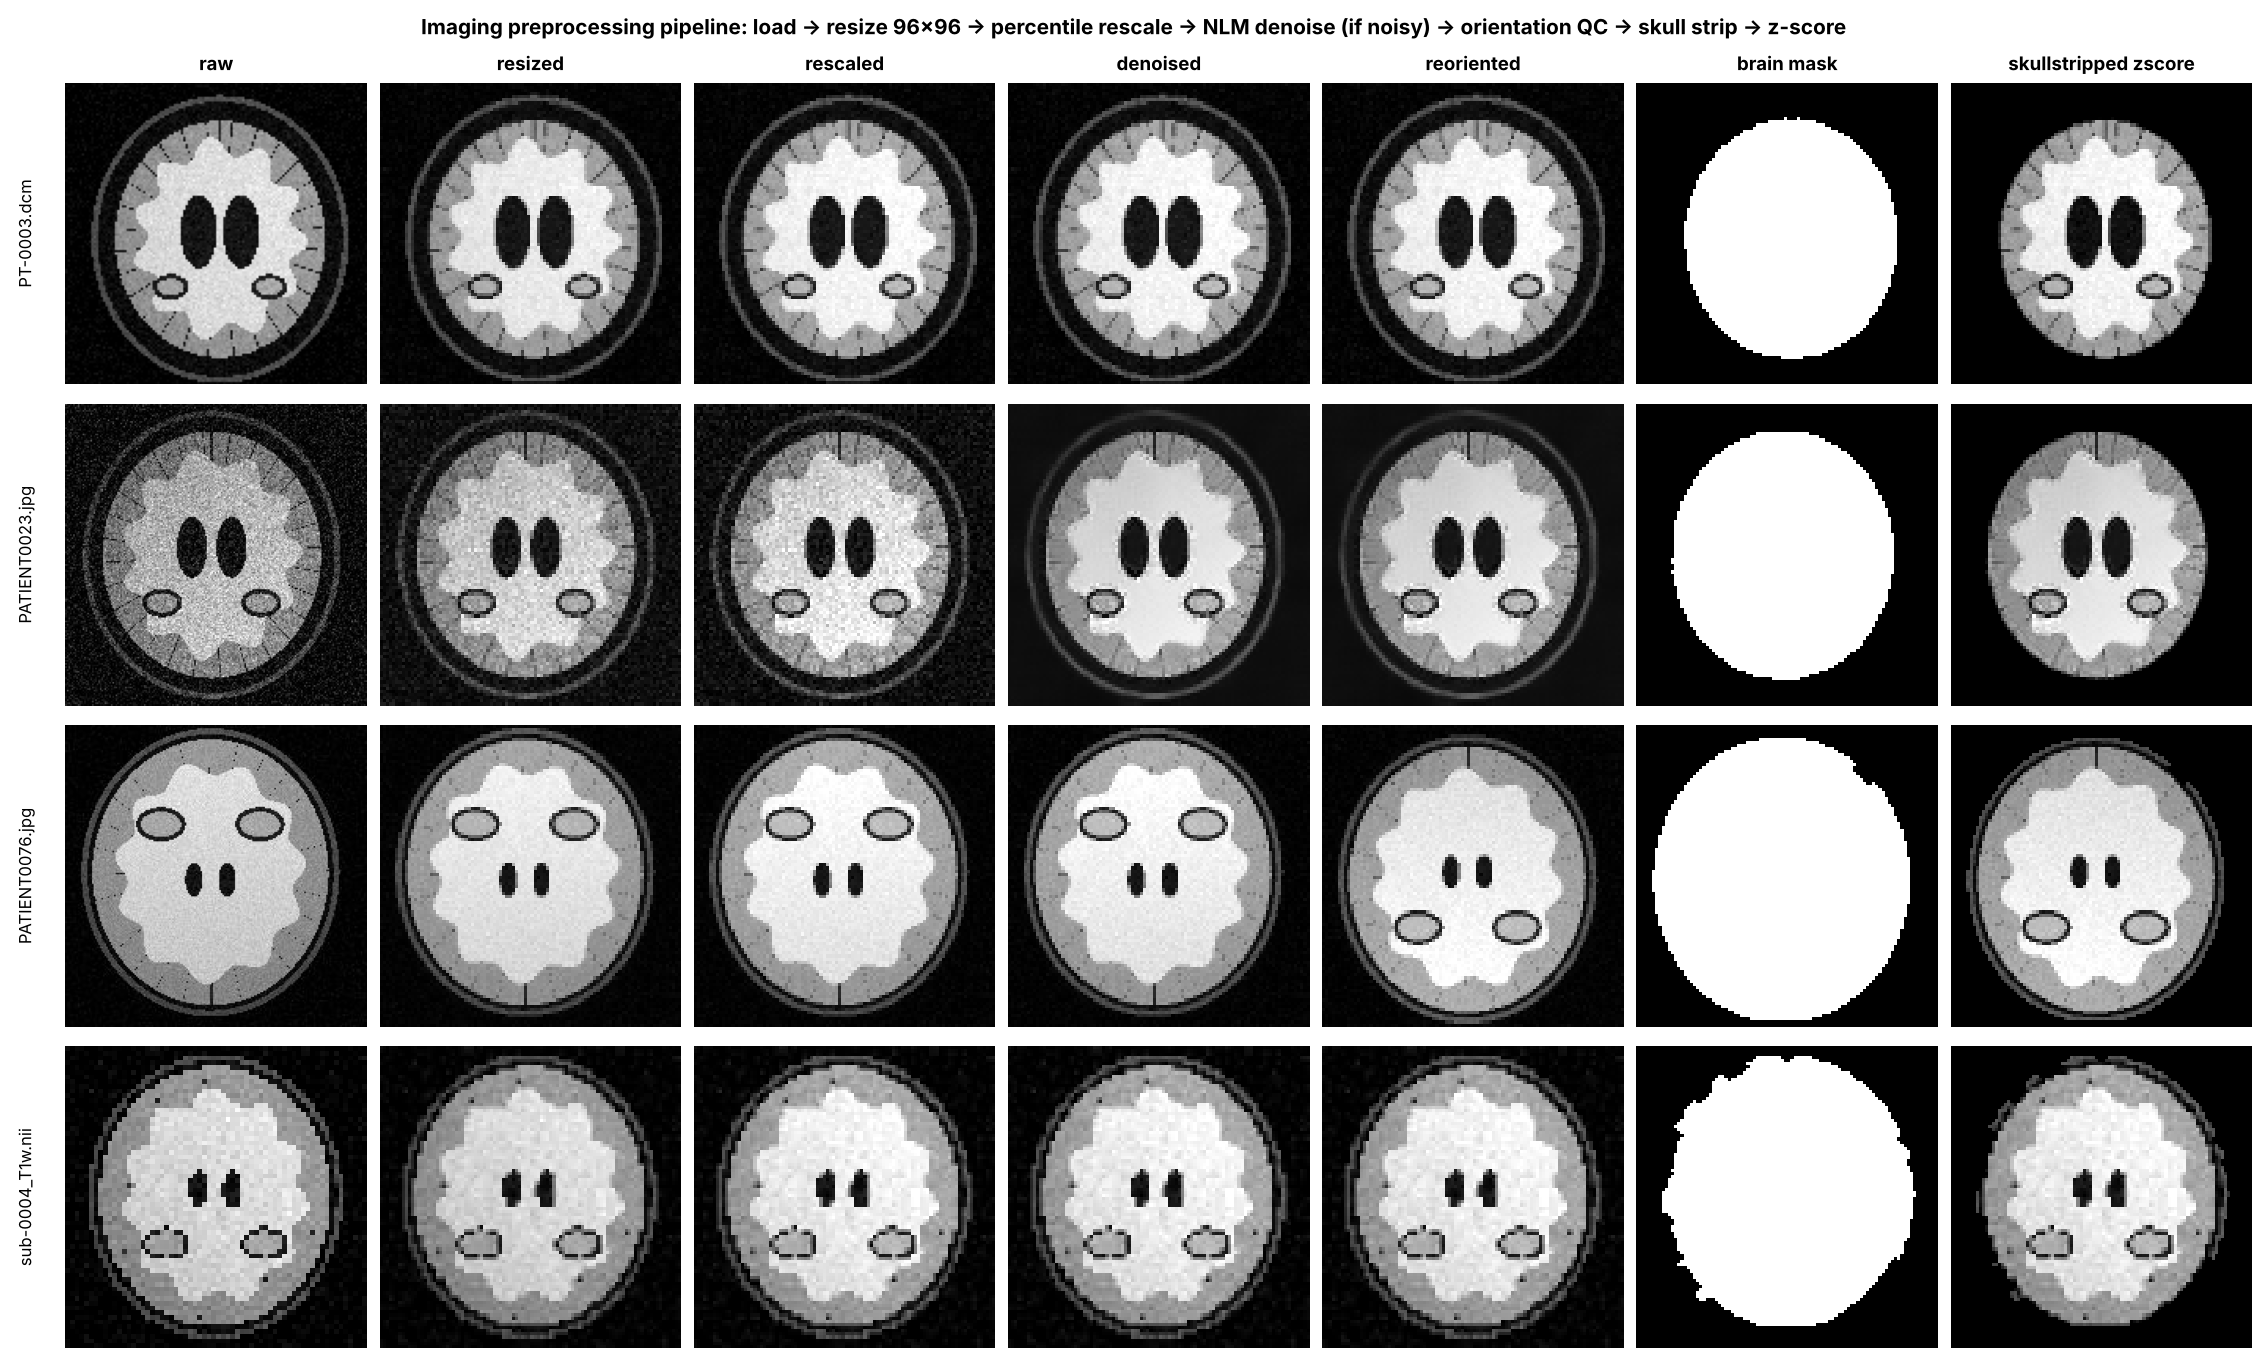

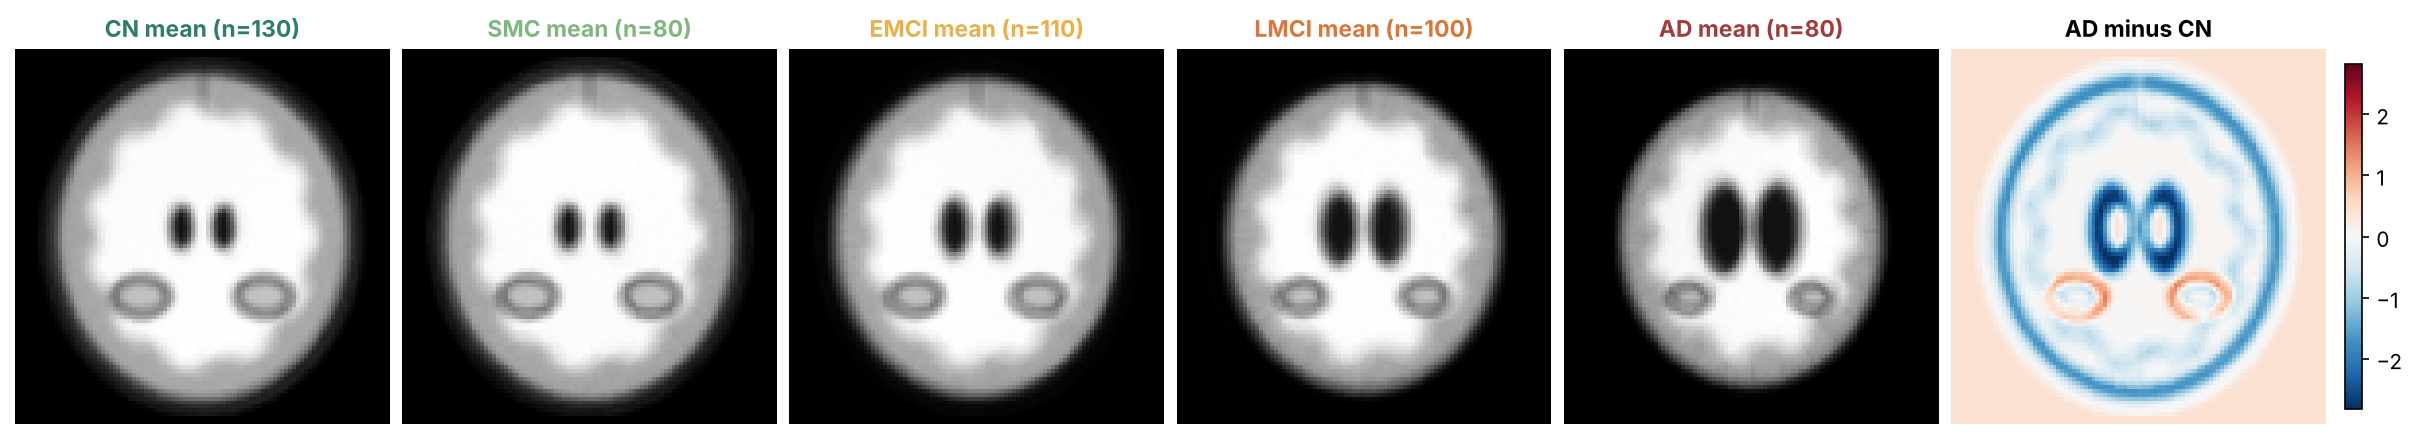

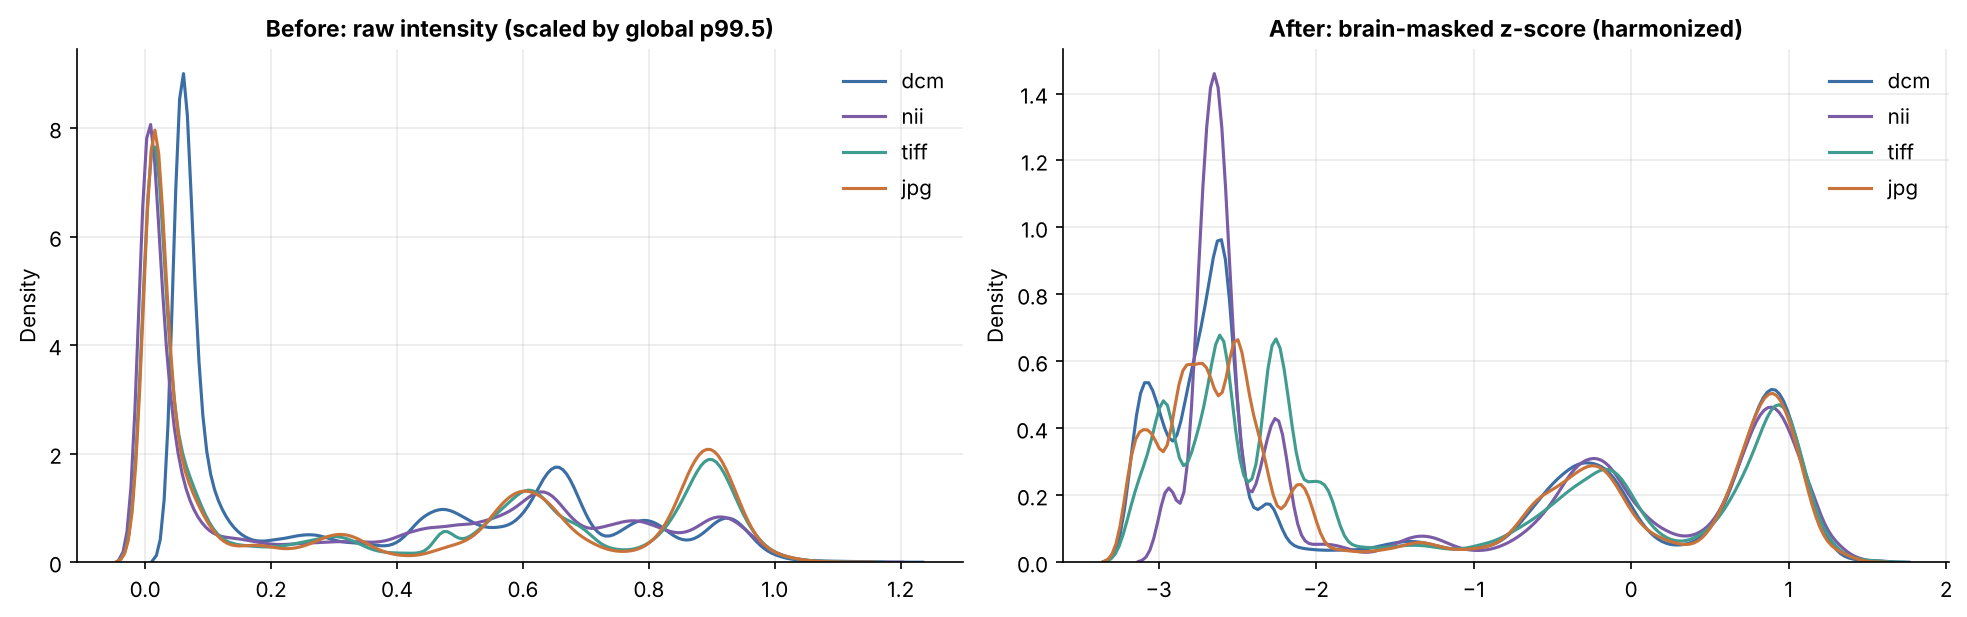

In [2]:
for n in ['07_img_preprocessing_steps', '08_img_class_mean_maps', '09_img_intensity_harmonization']: show(n)

In [3]:
log = json.load(open(ROOT / 'reports/metrics/preprocessing_log.json'))
print(json.dumps(log, indent=1))

{
 "imaging": {
  "studies": 500,
  "by_format": {
   "tiff": 125,
   "dcm": 125,
   "nii": 125,
   "jpg": 125
  },
  "flip_corrected": 4,
  "denoised": 2
 },
 "text": {
  "rows_raw": 514,
  "exact_duplicates_removed": 6,
  "empty_notes": 3,
  "rows_clean": 508,
  "truncated_notes": 1
 },
 "tabular": {
  "rows_raw": 515,
  "duplicates_removed": 15,
  "unmapped_dx": 0,
  "hippocampus_cm3_to_mm3": 103,
  "age_decimal_fix": 3,
  "mmse_decimal_fix": 3,
  "implausible_set_nan": 0,
  "missing_cells": 218,
  "rows_clean": 500
 },
 "merge": {
  "image_ids": 500,
  "note_ids": 508,
  "tabular_ids": 500,
  "notes_without_image_or_tabular(orphans)": 8,
  "all_three": 500
 },
 "final": {
  "rows": 500,
  "image_tensor": [
   500,
   1,
   96,
   96
  ],
  "text_tensor": [
   500,
   96
  ],
  "tabular_tensor": [
   500,
   22
  ],
  "split": {
   "train": 350,
   "test": 75,
   "val": 75
  },
  "class_counts": {
   "CN": 130,
   "EMCI": 110,
   "LMCI": 100,
   "AD": 80,
   "SMC": 80
  },
  "vocab_

In [4]:
ds = pd.read_csv(ROOT / 'data/processed/multimodal_dataset.csv')
print(ds.shape); display(ds[['patient_id', 'label', 'split', 'format', 'note_clean', 'age', 'mmse', 'ptau217_pg_ml']].head())
for f in ['images', 'input_ids', 'attention_mask', 'tabular_features']:
    print(f, np.load(ROOT / f'data/processed/{f}.npy').shape)

(500, 30)


,patient_id,label,split,format,note_clean,age,mmse,ptau217_pg_ml
0,PT-0001,CN,test,tiff,<num>-year-old male seen for routine cognitive...,83.0,29.0,0.236
1,PT-0002,LMCI,train,tiff,<num>-year-old female seen for memory lapses n...,72.0,25.0,1.047
2,PT-0003,AD,train,dcm,<num>-year-old male seen for worsening short-t...,75.0,23.0,1.038
3,PT-0004,CN,train,nii,<num>-year-old male seen for annual research f...,68.0,30.0,NaN
4,PT-0005,SMC,val,jpg,<num>-year-old male seen for self-referral for...,74.0,29.0,0.495


images (500, 1, 96, 96)
input_ids (500, 96)
attention_mask (500, 96)
tabular_features (500, 22)


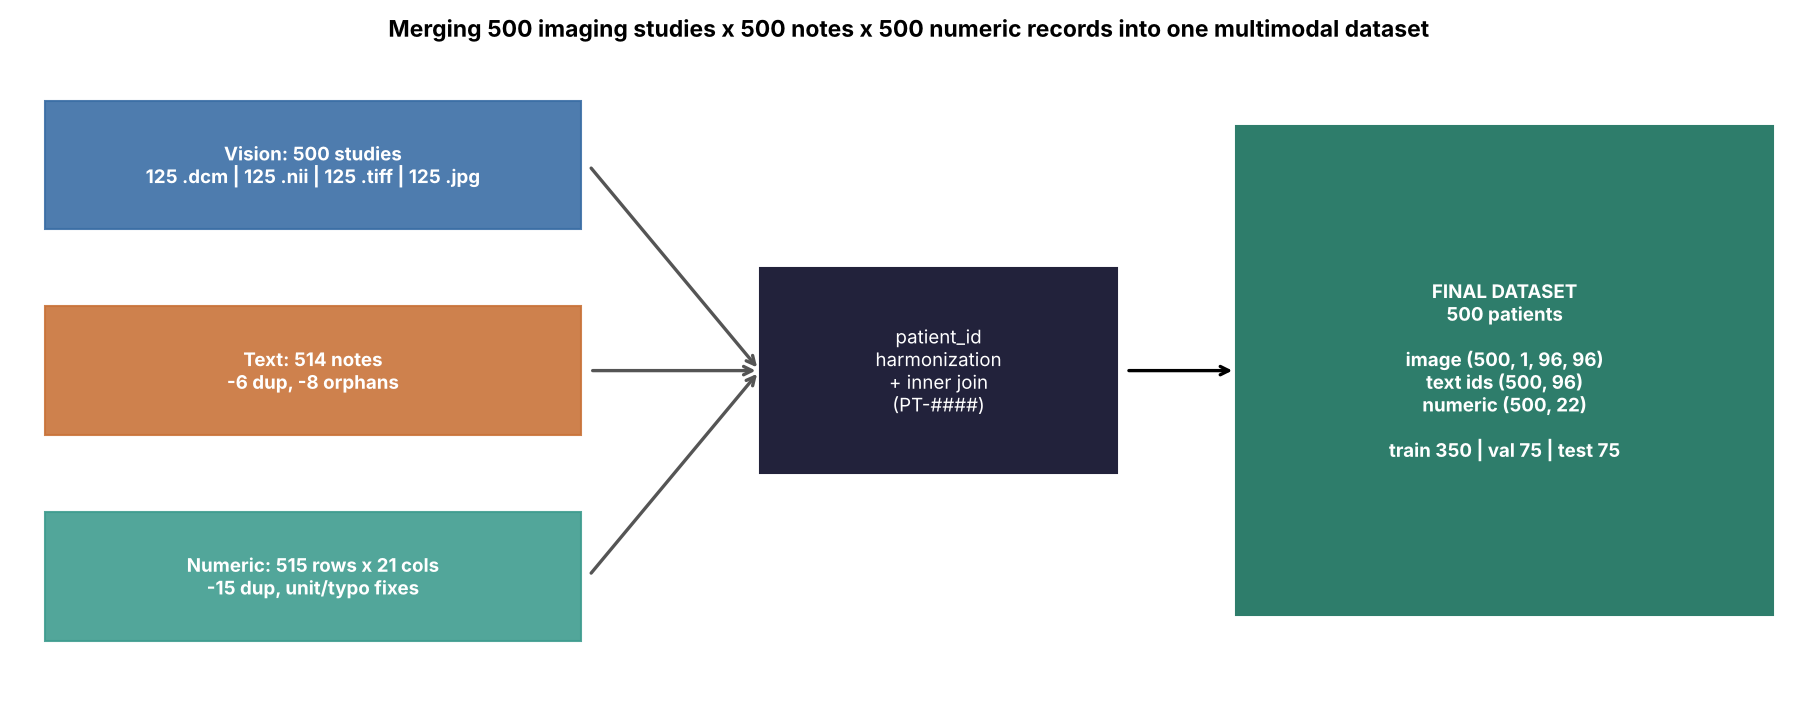

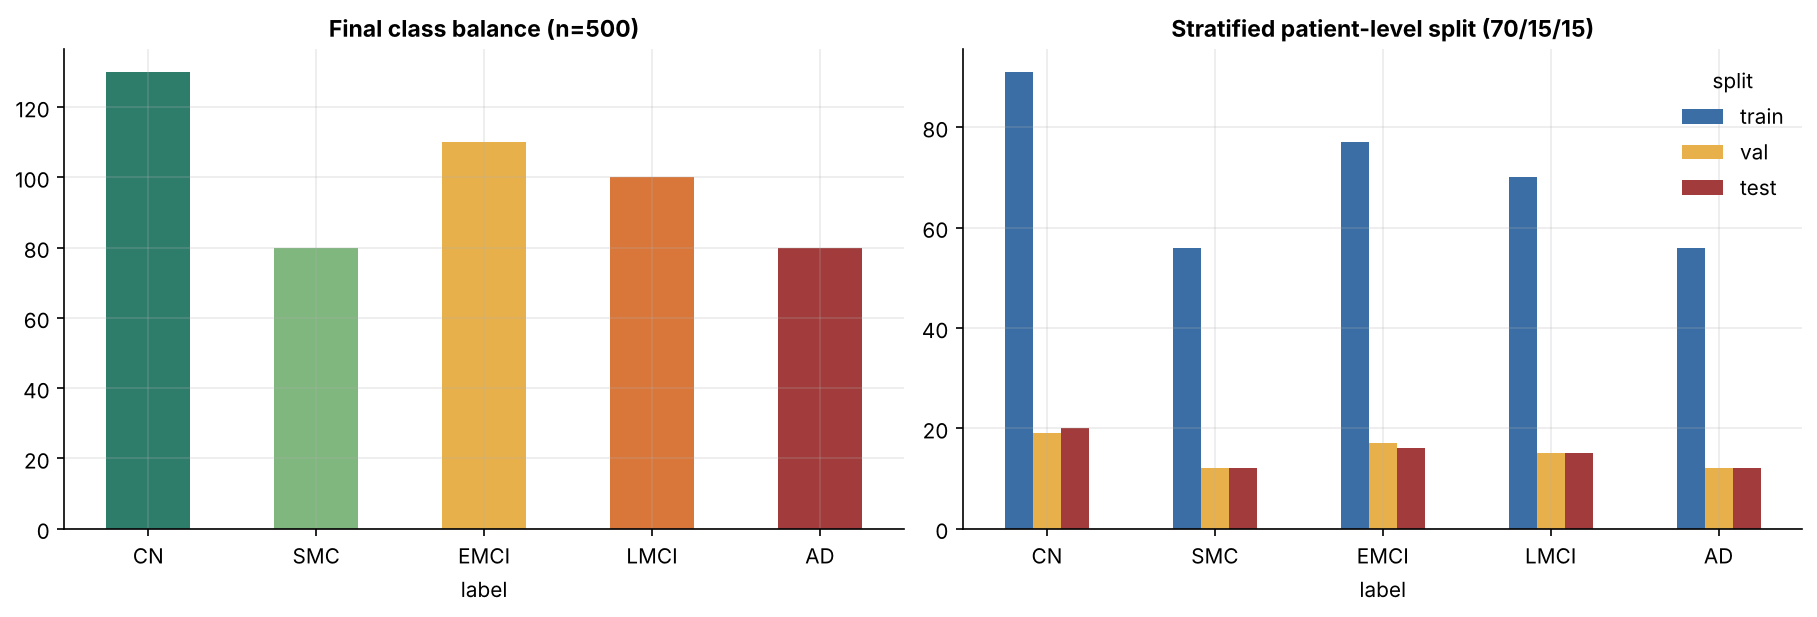

In [5]:
show('19_merge_flow'); show('20_final_class_balance_split')